In [8]:
import os
import sys
from IPython import get_ipython
import pandas as pd
import importlib

# Add parent directory to path to import from helpers
current_dir = os.getcwd()
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

# Only add if not already in path
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

import helpers.process_data
from helpers.process_data import process_data, preprocess_data, in_fold_process_data

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt


In [9]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')


In [10]:
# Data preparation - no preprocessing yet (done in CV to avoid leakage)
# Extract target from training data
y_train = train['target']

print("Data loaded:")
print(f"Training data shape: {train.shape}")
print(f"Test data shape: {test.shape}")
print("Target distribution:")
print(y_train.value_counts().sort_index())

print("\nTarget distribution percentages:")
target_counts = y_train.value_counts().sort_index()
for label, count in target_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {label}: {count:,} samples ({percentage:.1f}%)")

Data loaded:
Training data shape: (26206, 19)
Test data shape: (11232, 19)
Target distribution:
target
0    17423
1     8783
Name: count, dtype: int64

Target distribution percentages:
  Class 0: 17,423 samples (66.5%)
  Class 1: 8,783 samples (33.5%)


In [11]:
# LightGBM with 5-fold Cross Validation - NEW METHOD: Pre-CV preprocessing + In-fold processing
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import numpy as np

# Initialize LightGBM classifier parameters with AUC as eval metric
base_lgb_params = {
    'random_state': 42,
    'n_estimators': 100,
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'verbose': -1,
    'metric': 'logloss'
}

print("=" * 70)
print("5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING")
print("(Pre-CV preprocessing + In-fold imputation/encoding)")
print("=" * 70)

# Prepare raw data
raw_train_features = train.drop('target', axis=1)
y_train = train['target']

print(f"\nRaw training data shape: {raw_train_features.shape}")
print(f"Target shape: {y_train.shape}")

# STEP 1: Pre-CV preprocessing (no data leakage - done once before CV)
print("\n" + "="*70)
print("STEP 1: PRE-CV PREPROCESSING (No Leakage)")
print("="*70)
print("Extracting features that don't cause data leakage...")
print("(Textual features, ratios, engineered features)")

X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)

print(f"\nPreprocessed data shape: {X_preprocessed.shape}")
print(f"Missing values in preprocessed data: {X_preprocessed.isnull().sum().sum()}")

# STEP 2: Cross-validation with in-fold processing
print("\n" + "="*70)
print("STEP 2: CROSS-VALIDATION WITH IN-FOLD PROCESSING")
print("="*70)
print("Imputation and encoding will be done within each fold to prevent leakage")

# 5-fold stratified cross validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_acc = []
cv_scores_auc = []
fold_details = []

print(f"\nStarting 5-fold cross validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
    print(f"\n{'='*20} FOLD {fold}/5 {'='*20}")
    
    # Split preprocessed data into train/validation for this fold
    X_train_fold = X_preprocessed.iloc[train_idx]
    X_val_fold = X_preprocessed.iloc[val_idx]
    y_train_fold = y_train.iloc[train_idx]
    y_val_fold = y_train.iloc[val_idx]
    
    print(f"Fold {fold} - Train: {X_train_fold.shape}, Val: {X_val_fold.shape}")
    
    # In-fold processing: imputation and encoding (fit on train, transform both)
    print("Performing in-fold processing (imputation & encoding)...")
    X_train_processed, X_val_processed, impute_vals = in_fold_process_data(
        X_train_fold, X_val_fold,
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=False
    )
    
    print(f"Processed - Train: {X_train_processed.shape}, Val: {X_val_processed.shape}")
    
    # Verify no missing values
    train_missing = X_train_processed.isnull().sum().sum()
    val_missing = X_val_processed.isnull().sum().sum()
    
    if train_missing > 0 or val_missing > 0:
        print(f"WARNING: Missing values detected! Train: {train_missing}, Val: {val_missing}")
    
    # Train LightGBM on this fold
    print("Training LightGBM...")
    lgb_fold = lgb.LGBMClassifier(**base_lgb_params)
    lgb_fold.fit(
        X_train_processed, y_train_fold,
        eval_set=[(X_val_processed, y_val_fold)],
        eval_metric='logloss'
    )
    
    # Validate on this fold
    val_predictions = lgb_fold.predict(X_val_processed)
    val_probabilities = lgb_fold.predict_proba(X_val_processed)[:, 1]
    
    fold_score_acc = accuracy_score(y_val_fold, val_predictions)
    fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
    
    cv_scores_acc.append(fold_score_acc)
    cv_scores_auc.append(fold_score_auc)
    
    print(f"Fold {fold} - Accuracy: {fold_score_acc:.4f}, AUC: {fold_score_auc:.4f}")
    
    # Store fold details
    fold_details.append({
        'fold': fold,
        'train_size': len(y_train_fold),
        'val_size': len(y_val_fold),
        'accuracy': fold_score_acc,
        'auc': fold_score_auc,
        'features': X_train_processed.shape[1]
    })

print(f"\n{'='*70}")
print("CROSS VALIDATION RESULTS")
print(f"{'='*70}")

cv_scores_acc = np.array(cv_scores_acc)
cv_scores_auc = np.array(cv_scores_auc)

print("\nAccuracy Scores:")
print(f"  Individual fold scores: {cv_scores_acc}")
print(f"  Mean CV accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")

print("\nAUC Scores:")
print(f"  Individual fold scores: {cv_scores_auc}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

# Display fold details
print(f"\nFold Details:")
for detail in fold_details:
    print(f"  Fold {detail['fold']}: {detail['train_size']:,} train, {detail['val_size']:,} val, "
          f"{detail['features']} features, Acc: {detail['accuracy']:.4f}, AUC: {detail['auc']:.4f}")

# STEP 3: Train final model on full dataset
print(f"\n{'='*70}")
print("STEP 3: TRAINING FINAL MODEL ON FULL DATASET")
print(f"{'='*70}")

# Pre-process full training data
print("Pre-processing full training dataset...")
X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)

# For final model, we need to do imputation/encoding on the full dataset
# We'll use a dummy split to apply in_fold_process_data
# (In production, you'd create a separate function for this, but this works)
print("Processing full dataset (imputation & encoding)...")

# Create a dummy validation set (just use a small portion for the function call)
dummy_train_idx = range(len(X_preprocessed_full))
dummy_val_idx = range(min(100, len(X_preprocessed_full)))

X_train_final, _, impute_vals_final = in_fold_process_data(
    X_preprocessed_full, 
    X_preprocessed_full.iloc[dummy_val_idx],
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=True
)

print("Training final LightGBM model...")
lgb_model = lgb.LGBMClassifier(**base_lgb_params)
lgb_model.fit(X_train_final, y_train)

# Training metrics
train_predictions = lgb_model.predict(X_train_final)
train_probabilities = lgb_model.predict_proba(X_train_final)[:, 1]
train_accuracy = accuracy_score(y_train, train_predictions)
train_auc = roc_auc_score(y_train, train_probabilities)

print(f"Final model training accuracy: {train_accuracy:.4f}")
print(f"Final model training AUC: {train_auc:.4f}")

# Feature importance
feature_importance = lgb_model.feature_importances_
feature_names = X_train_final.columns
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print("\nTop 10 Most Important Features:")
print(importance_df.head(10))

# Store variables for later use
X_train = X_train_final  # For compatibility with evaluation cell
imputation_values_final = impute_vals_final  # For test data processing


5-FOLD CROSS VALIDATION WITH OPTIMIZED PREPROCESSING
(Pre-CV preprocessing + In-fold imputation/encoding)

Raw training data shape: (26206, 18)
Target shape: (26206,)

STEP 1: PRE-CV PREPROCESSING (No Leakage)
Extracting features that don't cause data leakage...
(Textual features, ratios, engineered features)
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)
  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (4

In [ ]:
# Generate predictions on test set with consistent preprocessing
import joblib
import os

print("=" * 60)
print("GENERATING TEST PREDICTIONS")
print("=" * 60)

# STEP 1: Pre-process test data (same as training)
print("\nStep 1: Pre-processing test data (textual features, ratios, etc.)...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

print(f"Test data preprocessed shape: {X_test_preprocessed.shape}")
print(f"Missing values: {X_test_preprocessed.isnull().sum().sum()}")

# STEP 2: Apply imputation and encoding using values from training
print("\nStep 2: Applying imputation & encoding (using training statistics)...")

# We need to apply the same transformations as training
# Use a dummy validation set approach (this ensures consistency)
dummy_val_idx = range(min(100, len(X_test_preprocessed)))

_, X_test_processed, _ = in_fold_process_data(
    X_train_final.iloc[:100],  # Use small sample from train to fit encoders
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=False
)

print(f"Test data processed shape: {X_test_processed.shape}")
print(f"Training data shape: {X_train.shape}")

# Ensure feature consistency
print("\nFeature consistency check:")
print(f"  Same number of columns: {X_train.shape[1] == X_test_processed.shape[1]}")

# If columns don't match, align them
if X_train.shape[1] != X_test_processed.shape[1]:
    print("  Column count mismatch - aligning features...")
    
    # Get missing columns
    missing_cols = set(X_train.columns) - set(X_test_processed.columns)
    extra_cols = set(X_test_processed.columns) - set(X_train.columns)
    
    # Add missing columns with zeros
    for col in missing_cols:
        X_test_processed[col] = 0
        print(f"    Added missing column: {col}")
    
    # Remove extra columns
    for col in extra_cols:
        X_test_processed = X_test_processed.drop(columns=[col])
        print(f"    Removed extra column: {col}")
    
    # Reorder to match training
    X_test_processed = X_test_processed[X_train.columns]
    
    print(f"  Aligned test data shape: {X_test_processed.shape}")

print(f"  Column names match: {list(X_train.columns) == list(X_test_processed.columns)}")

if X_train.shape[1] == X_test_processed.shape[1] and list(X_train.columns) == list(X_test_processed.columns):
    print("  ✓ Perfect feature consistency between train and test")
else:
    print("  ⚠ Feature inconsistency detected - predictions may be unreliable")

# Generate predictions
print("\nGenerating predictions on test set...")
test_probabilities = lgb_model.predict_proba(X_test_processed)[:, 1]

# Create submission dataframe
submission = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities
})

# Save submission file to submissions folder
os.makedirs('../submissions', exist_ok=True)
submission_path = '../submissions/LightGBM.csv'
submission.to_csv(submission_path, index=False)

# Save trained model to models/trained folder
os.makedirs('trained', exist_ok=True)
model_path = 'trained/lgb_model.joblib'
joblib.dump(lgb_model, model_path)

print(f"\nSubmission file saved to: {submission_path}")
print(f"Trained model saved to: {model_path}")
print("\nPrediction statistics:")
print(f"  Range: {test_probabilities.min():.4f} to {test_probabilities.max():.4f}")
print(f"  Mean:  {test_probabilities.mean():.4f}")
print(f"  Std:   {test_probabilities.std():.4f}")
print(f"  Shape: {submission.shape}")

# Display first few predictions
print("\nFirst 10 predictions:")
print(submission.head(10))


GENERATING TEST PREDICTIONS

Step 1: Pre-processing test data (textual features, ratios, etc.)...
Test data preprocessed shape: (11232, 33)
Missing values: 0

Step 2: Applying imputation & encoding (using training statistics)...
Test data processed shape: (11232, 33)
Training data shape: (26206, 81)

Feature consistency check:
  Same number of columns: False
  Column count mismatch - aligning features...
    Added missing column: lang_fa
    Added missing column: lang_pl
    Added missing column: lang_ru
    Added missing column: lang_vi
    Added missing column: lang_nl
    Added missing column: lang_sq
    Added missing column: lang_tl
    Added missing column: lang_sv
    Added missing column: lang_el
    Added missing column: lang_bg
    Added missing column: lang_cs
    Added missing column: lang_sw
    Added missing column: lang_pt
    Added missing column: lang_zh-tw
    Added missing column: lang_hu
    Added missing column: lang_id
    Added missing column: lang_hi
    Added m

In [13]:
# Comprehensive Model Evaluation
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

print("=" * 60)
print("COMPREHENSIVE MODEL EVALUATION")
print("=" * 60)

# Generate predictions and probabilities
train_pred_proba = lgb_model.predict_proba(X_train)[:, 1]
train_predictions = lgb_model.predict(X_train)

# 1. Classification Report
print("\n1. CLASSIFICATION REPORT (Training Data):")
print("-" * 40)
print(classification_report(y_train, train_predictions))

# 2. Confusion Matrix
print("2. CONFUSION MATRIX (Training Data):")
print("-" * 40)
cm = confusion_matrix(y_train, train_predictions)
print(f"Confusion Matrix:\n{cm}")

# Extract values for better interpretation
tn, fp, fn, tp = cm.ravel()
print("\nConfusion Matrix Breakdown:")
print(f"True Negatives (TN):  {tn:,}")
print(f"False Positives (FP): {fp:,}")
print(f"False Negatives (FN): {fn:,}")
print(f"True Positives (TP):  {tp:,}")

# 3. Additional Metrics
print("\n3. DETAILED METRICS:")
print("-" * 40)
from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_train, train_predictions)
precision = precision_score(y_train, train_predictions)
recall = recall_score(y_train, train_predictions)
f1 = f1_score(y_train, train_predictions)
roc_auc = roc_auc_score(y_train, train_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

# 4. Calculate Average Precision (PR AUC)
avg_precision = average_precision_score(y_train, train_pred_proba)
print(f"PR AUC:    {avg_precision:.4f}")

# 5. Class Distribution Analysis
print("\n4. CLASS DISTRIBUTION ANALYSIS:")
print("-" * 40)
class_counts = y_train.value_counts().sort_index()
print("True class distribution:")
for class_label, count in class_counts.items():
    percentage = (count / len(y_train)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

print("\nPredicted class distribution:")
pred_counts = pd.Series(train_predictions).value_counts().sort_index()
for class_label, count in pred_counts.items():
    percentage = (count / len(train_predictions)) * 100
    print(f"  Class {class_label}: {count:,} samples ({percentage:.1f}%)")

# 6. Probability Distribution Analysis
print("\n5. PROBABILITY DISTRIBUTION ANALYSIS:")
print("-" * 40)
print("Probability statistics:")
print(f"  Min probability:  {train_pred_proba.min():.4f}")
print(f"  Max probability:  {train_pred_proba.max():.4f}")
print(f"  Mean probability: {train_pred_proba.mean():.4f}")
print(f"  Std probability:  {train_pred_proba.std():.4f}")

# Analyze predictions by class
bot_probs = train_pred_proba[y_train == 1]
human_probs = train_pred_proba[y_train == 0]

print("\nProbability by true class:")
print(f"  Bots (Class 1) - Mean: {bot_probs.mean():.4f}, Std: {bot_probs.std():.4f}")
print(f"  Humans (Class 0) - Mean: {human_probs.mean():.4f}, Std: {human_probs.std():.4f}")

# 7. Model Performance Summary
print("\n6. MODEL PERFORMANCE SUMMARY:")
print("-" * 40)
print("Cross-Validation Performance:")
print(f"  Mean CV Accuracy: {cv_scores_acc.mean():.4f} (+/- {cv_scores_acc.std() * 2:.4f})")
print(f"  CV Accuracy Range: {cv_scores_acc.min():.4f} - {cv_scores_acc.max():.4f}")
print(f"  Mean CV AUC: {cv_scores_auc.mean():.4f} (+/- {cv_scores_auc.std() * 2:.4f})")
print(f"  CV AUC Range: {cv_scores_auc.min():.4f} - {cv_scores_auc.max():.4f}")

print("\nTraining Performance:")
print(f"  Training Accuracy: {accuracy:.4f}")
print(f"  Training ROC AUC:  {roc_auc:.4f}")

# Check for potential overfitting
cv_mean_acc = cv_scores_acc.mean()
overfitting_diff = accuracy - cv_mean_acc
print("\nOverfitting Check:")
print(f"  CV vs Train Accuracy Difference: {overfitting_diff:.4f}")
if overfitting_diff > 0.05:
    print("  Potential overfitting detected (difference > 0.05)")
elif overfitting_diff > 0.02:
    print("  Mild overfitting detected (difference > 0.02)")
else:
    print("  No significant overfitting detected")

print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)


COMPREHENSIVE MODEL EVALUATION

1. CLASSIFICATION REPORT (Training Data):
----------------------------------------
              precision    recall  f1-score   support

           0       0.91      0.96      0.93     17423
           1       0.91      0.81      0.86      8783

    accuracy                           0.91     26206
   macro avg       0.91      0.89      0.90     26206
weighted avg       0.91      0.91      0.91     26206

2. CONFUSION MATRIX (Training Data):
----------------------------------------
Confusion Matrix:
[[16722   701]
 [ 1626  7157]]

Confusion Matrix Breakdown:
True Negatives (TN):  16,722
False Positives (FP): 701
False Negatives (FN): 1,626
True Positives (TP):  7,157

3. DETAILED METRICS:
----------------------------------------
Accuracy:  0.9112
Precision: 0.9108
Recall:    0.8149
F1-Score:  0.8602
ROC AUC:   0.9650
PR AUC:    0.9448

4. CLASS DISTRIBUTION ANALYSIS:
----------------------------------------
True class distribution:
  Class 0: 17,423 sam

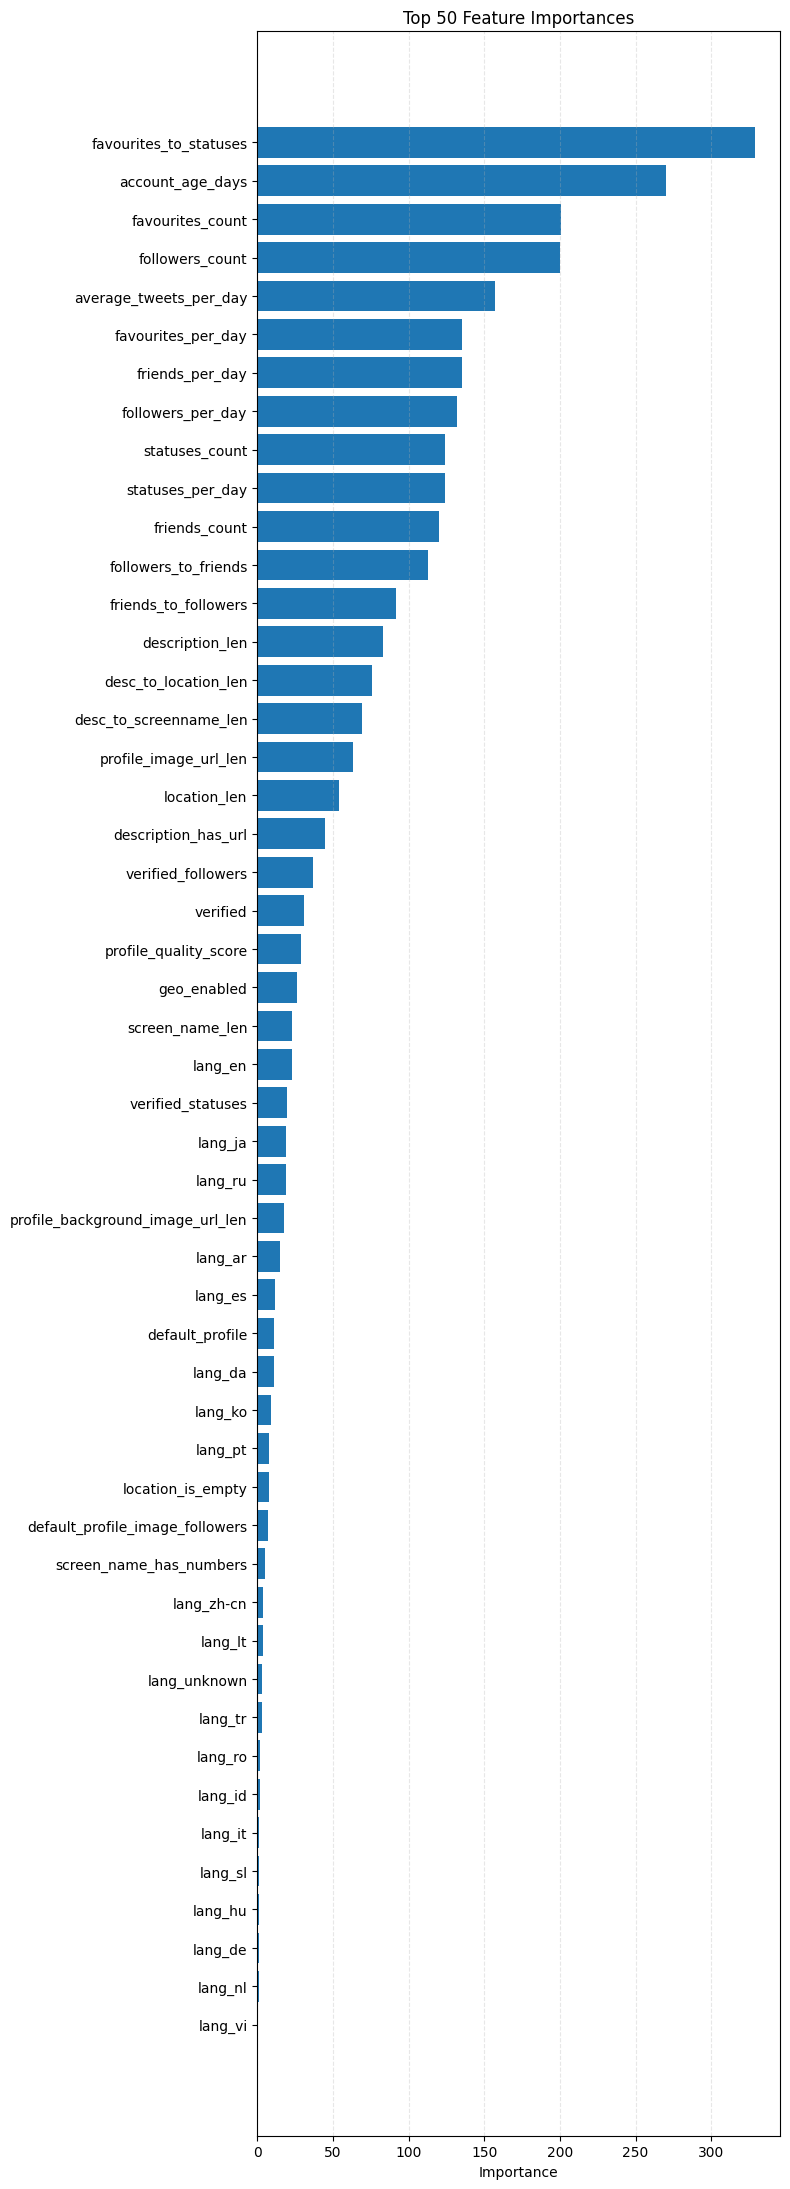

In [14]:
# Plot feature importances (uses importance_df created earlier)
# Show top N features as a horizontal bar chart
top_n = 50
top_df = importance_df.head(top_n).iloc[::-1]  # reverse for plotting

plt.figure(figsize=(8, 0.4 * len(top_df) + 2))
plt.barh(top_df['feature'], top_df['importance'], color='C0')
plt.xlabel('Importance')
plt.title(f'Top {top_n} Feature Importances')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Hyperparameter Optimization

### Optuna new should be faster

In [ ]:
# Optuna-based hyperparameter optimization for LightGBM with NEW preprocessing method
import optuna
from optuna.samplers import TPESampler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score
import time
import warnings
import joblib
import os
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)

# Check for GPU availability
try:
    import GPUtil
    gpus = GPUtil.getGPUs()
    gpu_available = len(gpus) > 0
    if gpu_available:
        print(f"GPU detected: {gpus[0].name} with {gpus[0].memoryFree}MB free memory")
    else:
        print("No GPU detected, using CPU")
except ImportError:
    print("GPUtil not installed, assuming CPU usage")
    gpu_available = False

def perform_optuna_lightgbm_optimization(raw_train_features, y_train, n_trials=50, cv_folds=5, use_gpu=True):
    """
    Perform hyperparameter optimization for LightGBM using Optuna with NEW preprocessing method.
    Uses pre-CV preprocessing + in-fold imputation/encoding to prevent data leakage.
    Optimizes for AUC score.
    
    Parameters:
    raw_train_features: Raw training features (before preprocessing)
    y_train: Training target
    n_trials: Number of optimization trials (default 50)
    cv_folds: Number of cross-validation folds
    use_gpu: Whether to use GPU acceleration if available
    
    Returns:
    best_model: Best LightGBM model from optimization
    best_params: Best parameters found
    best_score_auc: Best cross-validation AUC score
    study: Optuna study object with optimization history
    X_train_full: Processed full training data
    importance_df_optuna: Feature importance dataframe
    """
    
    print("="*70)
    print("OPTUNA HYPERPARAMETER OPTIMIZATION FOR LIGHTGBM")
    print("="*70)
    print("\nOptuna uses Bayesian optimization (TPE sampler) for efficient")
    print("hyperparameter search, making it faster than grid search.")
    print("\nNEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding")
    print("Optimizing for AUC score")
    
    # Determine device based on GPU availability
    if use_gpu and gpu_available:
        device = 'gpu'
        print(f"\nUsing GPU acceleration with device='{device}'")
    else:
        device = 'cpu'
        print(f"\nUsing CPU with device='{device}'")
    
    # STEP 1: Pre-CV preprocessing (done once, no leakage)
    print("\n" + "="*70)
    print("STEP 1: PRE-CV PREPROCESSING")
    print("="*70)
    print("Extracting features that don't cause data leakage...")
    
    X_preprocessed = preprocess_data(raw_train_features, verbose=True, include_statuses_count=True)
    
    print(f"\nPreprocessed shape: {X_preprocessed.shape}")
    print(f"Missing values: {X_preprocessed.isnull().sum().sum()}")
    
    # Setup cross-validation
    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=42)
    
    print("\n" + "="*70)
    print("STEP 2: OPTIMIZATION WITH IN-FOLD PROCESSING")
    print("="*70)
    print(f"\nOptimization Overview:")
    print(f"   Number of trials: {n_trials}")
    print(f"   Cross-validation folds: {cv_folds}")
    print(f"   Total model fits: {n_trials * cv_folds}")
    print(f"   Estimated time: {(n_trials * 20) / 60:.1f}-{(n_trials * 60) / 60:.1f} minutes\n")
    
    # Define objective function for Optuna
    def objective(trial):
        # Suggest hyperparameters
        params = {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 20, 150),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 0.0, 1.0),
            'random_state': 42,
            'verbose': -1,
            'device': device,
            'metric': 'logloss'
        }
        
        # Perform cross-validation with in-fold processing
        fold_scores_auc = []
        
        for fold, (train_idx, val_idx) in enumerate(skf.split(X_preprocessed, y_train), 1):
            # Split preprocessed data
            X_train_fold = X_preprocessed.iloc[train_idx]
            X_val_fold = X_preprocessed.iloc[val_idx]
            y_train_fold = y_train.iloc[train_idx]
            y_val_fold = y_train.iloc[val_idx]
            
            # In-fold processing (fit on train, transform both)
            X_train_processed, X_val_processed, _ = in_fold_process_data(
                X_train_fold, X_val_fold,
                imputation_strategy='median',
                categorical_encoding='onehot',
                lang_frequency_threshold=0,
                verbose=False
            )
            
            # Train model
            model = lgb.LGBMClassifier(**params)
            model.fit(X_train_processed, y_train_fold)
            
            # Validate with AUC
            val_probabilities = model.predict_proba(X_val_processed)[:, 1]
            fold_score_auc = roc_auc_score(y_val_fold, val_probabilities)
            fold_scores_auc.append(fold_score_auc)
        
        # Return mean CV AUC score
        mean_score_auc = np.mean(fold_scores_auc)
        return mean_score_auc
    
    # Create Optuna study
    study = optuna.create_study(
        direction='maximize',
        sampler=TPESampler(seed=42)
    )
    
    # Run optimization
    print("Starting optimization...")
    start_time = time.time()
    
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    
    total_time = time.time() - start_time
    
    # Get best parameters
    best_params = study.best_params
    best_score = study.best_value
    
    print("\n" + "="*70)
    print("OPTIMIZATION COMPLETE!")
    print("="*70)
    print(f"\nTotal time: {total_time/60:.1f} minutes ({total_time:.0f} seconds)")
    print(f"Best Cross-Validation AUC Score: {best_score:.4f}")
    print("\nBest Parameters:")
    for param, value in best_params.items():
        print(f"   {param}: {value}")
    
    # Train final model with best parameters on full dataset
    print("\n" + "="*70)
    print("TRAINING FINAL MODEL WITH BEST PARAMETERS")
    print("="*70)
    
    best_params_full = best_params.copy()
    best_params_full.update({
        'random_state': 42,
        'verbose': -1,
        'device': device,
        'metric': 'logloss'
    })
    
    # Pre-process full training data
    print("\nPre-processing full training dataset...")
    X_preprocessed_full = preprocess_data(raw_train_features, verbose=False, include_statuses_count=True)
    
    # Process full dataset (imputation & encoding)
    print("Processing full dataset (imputation & encoding)...")
    dummy_val_idx = range(min(100, len(X_preprocessed_full)))
    X_train_full, _, _ = in_fold_process_data(
        X_preprocessed_full, 
        X_preprocessed_full.iloc[dummy_val_idx],
        imputation_strategy='median',
        categorical_encoding='onehot',
        lang_frequency_threshold=0,
        verbose=True
    )
    
    print("Training final model...")
    best_model = lgb.LGBMClassifier(**best_params_full)
    best_model.fit(X_train_full, y_train)
    
    # Training metrics
    train_predictions = best_model.predict(X_train_full)
    train_probabilities = best_model.predict_proba(X_train_full)[:, 1]
    train_accuracy = accuracy_score(y_train, train_predictions)
    train_auc = roc_auc_score(y_train, train_probabilities)
    
    print(f"Final model training accuracy: {train_accuracy:.4f}")
    print(f"Final model training AUC: {train_auc:.4f}")
    
    # Feature importance
    feature_importance = best_model.feature_importances_
    feature_names = X_train_full.columns
    importance_df_optuna = pd.DataFrame({
        'feature': feature_names,
        'importance': feature_importance
    }).sort_values('importance', ascending=False)
    
    print("\nTop 10 Most Important Features:")
    print(importance_df_optuna.head(10).to_string(index=False, float_format='%.4f'))
    
    # Optimization history analysis
    print("\n" + "="*70)
    print("OPTIMIZATION HISTORY ANALYSIS")
    print("="*70)
    
    trials_df = study.trials_dataframe()
    print(f"\nNumber of completed trials: {len(study.trials)}")
    print(f"AUC score range: {trials_df['value'].min():.4f} - {trials_df['value'].max():.4f}")
    print(f"AUC score std: {trials_df['value'].std():.4f}")
    print(f"Best trial number: {study.best_trial.number + 1}")
    
    # Show top 5 trials
    top_trials = trials_df.nlargest(5, 'value')[['value', 'number'] + 
                                                  [col for col in trials_df.columns if col.startswith('params_')]]
    print("\nTop 5 Trials:")
    print(top_trials.to_string(index=False, float_format='%.4f'))
    
    return best_model, best_params_full, best_score, study, X_train_full, importance_df_optuna

# Run Optuna optimization
print("Starting Optuna hyperparameter optimization with NEW preprocessing method...\n")

# Prepare raw data
raw_train_features = train.drop('target', axis=1)
y_train = train['target']

# Run optimization with 50 trials (you can adjust this number)
# More trials = better optimization but longer runtime
# 50 trials typically gives good results in reasonable time
best_model_optuna, best_params_optuna, best_score_optuna, study_optuna, X_train_optuna, importance_df_optuna = perform_optuna_lightgbm_optimization(
    raw_train_features, y_train, 
    n_trials=50,  # Adjust this: 50 is good balance, 100+ for better results
    cv_folds=5, 
    use_gpu=True
)

# Generate predictions on test set
print("\n" + "="*70)
print("GENERATING TEST PREDICTIONS")
print("="*70)

# Pre-process test data
print("\nPre-processing test data...")
X_test_preprocessed = preprocess_data(test, verbose=False, include_statuses_count=True)

# Apply imputation & encoding
print("Applying imputation & encoding...")
dummy_val_idx = range(min(100, len(X_test_preprocessed)))
_, X_test_optuna, _ = in_fold_process_data(
    X_train_optuna.iloc[:100],
    X_test_preprocessed,
    imputation_strategy='median',
    categorical_encoding='onehot',
    lang_frequency_threshold=0,
    verbose=False
)

print(f"\nProcessed test data shape: {X_test_optuna.shape}")
print(f"Training data shape: {X_train_optuna.shape}")

# Ensure feature consistency
if X_train_optuna.shape[1] != X_test_optuna.shape[1]:
    print("\nAligning features...")
    missing_cols = set(X_train_optuna.columns) - set(X_test_optuna.columns)
    extra_cols = set(X_test_optuna.columns) - set(X_train_optuna.columns)
    
    for col in missing_cols:
        X_test_optuna[col] = 0
    for col in extra_cols:
        X_test_optuna = X_test_optuna.drop(columns=[col])
    
    X_test_optuna = X_test_optuna[X_train_optuna.columns]

# Verify consistency
print("\nConsistency check:")
print(f"  Same number of columns: {X_train_optuna.shape[1] == X_test_optuna.shape[1]}")
print(f"  Column names match: {list(X_train_optuna.columns) == list(X_test_optuna.columns)}")

# Generate predictions
print("\nGenerating predictions...")
start_time = time.time()
test_probabilities_optuna = best_model_optuna.predict_proba(X_test_optuna)[:, 1]
prediction_time = time.time() - start_time

print(f"Predictions complete in {prediction_time:.2f} seconds")
print("\nPrediction statistics:")
print(f"   Range: {test_probabilities_optuna.min():.4f} to {test_probabilities_optuna.max():.4f}")
print(f"   Mean: {test_probabilities_optuna.mean():.4f}")
print(f"   Std: {test_probabilities_optuna.std():.4f}")

# Create submission
submission_optuna = pd.DataFrame({
    'index': test['index'],
    'target': test_probabilities_optuna
})

# Save submission file to submissions folder
os.makedirs('../submissions', exist_ok=True)
submission_path_optuna = '../submissions/LightGBM_optuna.csv'
submission_optuna.to_csv(submission_path_optuna, index=False)

# Save trained model to models/trained folder
os.makedirs('trained', exist_ok=True)
model_path_optuna = 'trained/lgb_model_optuna.joblib'
joblib.dump(best_model_optuna, model_path_optuna)

# Save study object for further analysis
study_path = 'trained/optuna_study_lgb.joblib'
joblib.dump(study_optuna, study_path)

print(f"\nSubmission saved to: {submission_path_optuna}")
print(f"Optuna-tuned model saved to: {model_path_optuna}")
print(f"Optuna study saved to: {study_path}")

print("\nFirst 10 predictions:")
print(submission_optuna.head(10))

print("\n" + "="*70)
print("OPTUNA OPTIMIZATION COMPLETE!")
print("="*70)
print(f"\nBest CV AUC Score: {best_score_optuna:.4f}")
print("\nYou can visualize the optimization history using:")
print("   optuna.visualization.plot_optimization_history(study_optuna)")
print("   optuna.visualization.plot_param_importances(study_optuna)")
print("\nTo reload the saved study later:")
print(f"   study = joblib.load('{study_path}')")


No GPU detected, using CPU
Starting Optuna hyperparameter optimization with NEW preprocessing method...

OPTUNA HYPERPARAMETER OPTIMIZATION FOR LIGHTGBM

Optuna uses Bayesian optimization (TPE sampler) for efficient
hyperparameter search, making it faster than grid search.

NEW METHOD: Pre-CV preprocessing + In-fold imputation/encoding
Optimizing for AUC score

Using CPU with device='cpu'

STEP 1: PRE-CV PREPROCESSING
Extracting features that don't cause data leakage...
=== Pre-CV Data Preprocessing (No Leakage) ===
Original dataframe shape: (26206, 18)

Extracting numerical features...
  - favourites_count: extracted (missing: 0)
  - followers_count: extracted (missing: 0)
  - friends_count: extracted (missing: 0)
  - average_tweets_per_day: extracted (missing: 0)
  - account_age_days: extracted (missing: 0)
  - statuses_count: extracted (missing: 0)

Extracting binary features...
  - default_profile: extracted (missing: 0)
  - default_profile_image: extracted (missing: 0)


[I 2025-10-06 12:49:45,585] A new study created in memory with name: no-name-40b0261e-420d-4a17-b728-c40003bf426d


  - geo_enabled: extracted (missing: 0)
  - verified: extracted (missing: 0)

Extracting categorical features...
  - lang: extracted (49 categories)

Extracting textual features...
  - location_len: mean=11.05
  - description_len: mean=66.79
  - screen_name_len: mean=11.12
  - profile_background_image_url_len: mean=42.25
  - profile_image_url_len: mean=75.52
  - description_has_url: 3613 accounts (13.8%)
  - screen_name_has_numbers: 7015 accounts (26.8%)
  - location_is_empty: 9219 accounts (35.2%)
  - description_is_empty: 5091 accounts (19.4%)

Engineering features...
  - followers_per_day: mean=100.1868
  - friends_per_day: mean=1.3514
  - statuses_per_day: mean=6.7520
  - favourites_per_day: mean=4.5426
  - followers_to_friends: mean=17068.7325
  - friends_to_followers: mean=2.4651
  - favourites_to_statuses: mean=2.3652
  - default_profile_image_followers: mean=156.1863
  - verified_followers: mean=349050.1084
  - verified_statuses: mean=6533.1420
  - desc_to_screenname_len: mean=

Best trial: 0. Best value: 0.944483:   2%|▏         | 1/50 [00:24<19:57, 24.44s/it]

[I 2025-10-06 12:50:10,034] Trial 0 finished with value: 0.9444826717694308 and parameters: {'n_estimators': 250, 'max_depth': 10, 'learning_rate': 0.1205712628744377, 'num_leaves': 98, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'min_child_samples': 10, 'reg_alpha': 0.8661761457749352, 'reg_lambda': 0.6011150117432088}. Best is trial 0 with value: 0.9444826717694308.


...

[I 2025-10-06 12:59:31,555] Trial 47 finished with value: 0.9427670732048357 and parameters: {'n_estimators': 250, 'max_depth': 5, 'learning_rate': 0.03662295617356873, 'num_leaves': 54, 'subsample': 0.7375303912292759, 'colsample_bytree': 0.6850752030939213, 'min_child_samples': 19, 'reg_alpha': 0.835903037947658, 'reg_lambda': 0.4356302807905005}. Best is trial 46 with value: 0.9464275983861519.


Best trial: 46. Best value: 0.946428:  98%|█████████▊| 49/50 [10:00<00:13, 13.64s/it]

[I 2025-10-06 12:59:46,192] Trial 48 finished with value: 0.9459441561829746 and parameters: {'n_estimators': 400, 'max_depth': 8, 'learning_rate': 0.04864267702369553, 'num_leaves': 36, 'subsample': 0.6857439502630711, 'colsample_bytree': 0.7381504431514008, 'min_child_samples': 35, 'reg_alpha': 0.5707858743080367, 'reg_lambda': 0.2789232942495936}. Best is trial 46 with value: 0.9464275983861519.


Best trial: 46. Best value: 0.946428: 100%|██████████| 50/50 [10:17<00:00, 12.34s/it]



[I 2025-10-06 13:00:02,747] Trial 49 finished with value: 0.9458157915908922 and parameters: {'n_estimators': 350, 'max_depth': 7, 'learning_rate': 0.026772431747921533, 'num_leaves': 70, 'subsample': 0.7790293063725983, 'colsample_bytree': 0.6539633070565098, 'min_child_samples': 47, 'reg_alpha': 0.8883032942153046, 'reg_lambda': 0.49727501986014316}. Best is trial 46 with value: 0.9464275983861519.

OPTIMIZATION COMPLETE!

Total time: 10.3 minutes (617 seconds)
Best Cross-Validation AUC Score: 0.9464

Best Parameters:
   n_estimators: 300
   max_depth: 8
   learning_rate: 0.03452036021109606
   num_leaves: 55
   subsample: 0.7344425137826482
   colsample_bytree: 0.6915085646716037
   min_child_samples: 19
   reg_alpha: 0.7984377453462917
   reg_lambda: 0.4384174705954996

TRAINING FINAL MODEL WITH BEST PARAMETERS

Pre-processing full training dataset...
Processing full dataset (imputation & encoding)...
=== In-Fold Processing (Fit on Train, Transform Train & Val) ===
Train shape: (26

In [ ]:
# Visualize Optuna optimization results
# Note: If you get nbformat errors, run: pip install --upgrade nbformat
import joblib
import optuna

study_optuna = joblib.load('trained/optuna_study_lgb.joblib')
try:
    import plotly
    fig1 = optuna.visualization.plot_optimization_history(study_optuna)
    fig1.show()
    
    fig2 = optuna.visualization.plot_param_importances(study_optuna)
    fig2.show()
except Exception as e:
    print(f"Visualization error: {e}")
    print("\nTo fix this, run in terminal:")
    print("  pip install --upgrade nbformat plotly")
    print("\nAlternatively, you can view the optimization results as text:")
    print(f"\nBest trial: {study_optuna.best_trial.number}")
    print(f"Best value: {study_optuna.best_value:.4f}")
    print(f"Best params: {study_optuna.best_params}")
